# Demand Forecasting & Inventory Planning Simulator

Forecast weekly demand for five items two weeks ahead (the supplier lead time), compare four forecasting models, then use Monte Carlo simulation to set safety stock and reorder points for a 95% service level.

**Contents**
1. Data preparation and exploration
2. Baselines at a 52-week horizon
3. Forecasting at a 2-week horizon: seasonal naive, Holt-Winters, Poisson GLM, LightGBM
4. Inventory planning: safety stock, reorder points and Monte Carlo simulation

Data: `train.csv` from the Kaggle Store Item Demand Forecasting Challenge (not included; see the README).

## 1. Data preparation and exploration

### 1.1 Imports and data loading

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# parse_dates converts the 'date' strings into real datetime objects,
# which pandas needs for time-based grouping later
from pathlib import Path
ROOT = Path("..") if Path("../data").exists() else Path(".")
df = pd.read_csv(ROOT / "data" / "train.csv", parse_dates=["date"])
print(df.shape)
df.head()

(913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


### 1.2 Sanity checks, item selection and weekly aggregation

In [58]:
print(df["date"].min(), df["date"].max())      # expect 2013-01-01 to 2017-12-31
print(df.isna().sum())                          # expect no missing values
print(df["store"].nunique(), df["item"].nunique())  # expect 10 and 50
print(df["date"].min().day_name())              # what weekday does the data start on?

2013-01-01 00:00:00 2017-12-31 00:00:00
date     0
store    0
item     0
sales    0
dtype: int64
10 50
Tuesday


In [59]:
# Total units sold per item over the whole period, sorted low -> high
totals = df.groupby("item")["sales"].sum().sort_values()
# Pick 5 evenly spaced positions in that ranking: lowest, 25%, median, 75%, highest
positions = np.linspace(0, len(totals) - 1, 5).round().astype(int)
items = totals.index[positions].tolist()

print("Chosen items:", items)
print(totals.loc[items])

Chosen items: [5, 44, 48, 12, 15]
item
5      335230
44     536811
48     937703
12    1271534
15    1607442
Name: sales, dtype: int64


In [60]:
# Keep only our 5 items, then group by item and week.
# 'W-SUN' = weeks ending on Sunday (Mon-Sun weeks), labelled by that Sunday.
weekly = (
    df[df["item"].isin(items)]
    .groupby(["item", pd.Grouper(key="date", freq="W-SUN")])["sales"]
    .sum()
    .reset_index()
)

# The data starts on a Tuesday, so the first week (ending 2013-01-06) is
# missing a Monday. A partial week would look like artificially low demand,
# so we drop it. The last week (ending 2017-12-31) is complete.
weekly = weekly[weekly["date"] >= "2013-01-07"]
weekly# Wide format: one row per week, one column per item
wide = weekly.pivot(index="date", columns="item", values="sales")
print(wide.shape)   # expect (260, 5): 260 full weeks, 5 items
wide.head()

(260, 5)


item,5,12,15,44,48
date,,,,,
2013-01-13,692,2829,3519,1183,2060
2013-01-20,701,2731,3442,1226,1964
2013-01-27,742,2748,3491,1095,1973
2013-02-03,758,2952,3733,1236,2102
2013-02-10,785,3101,3882,1248,2191


### 1.3 Weekly demand by item: trend and seasonality

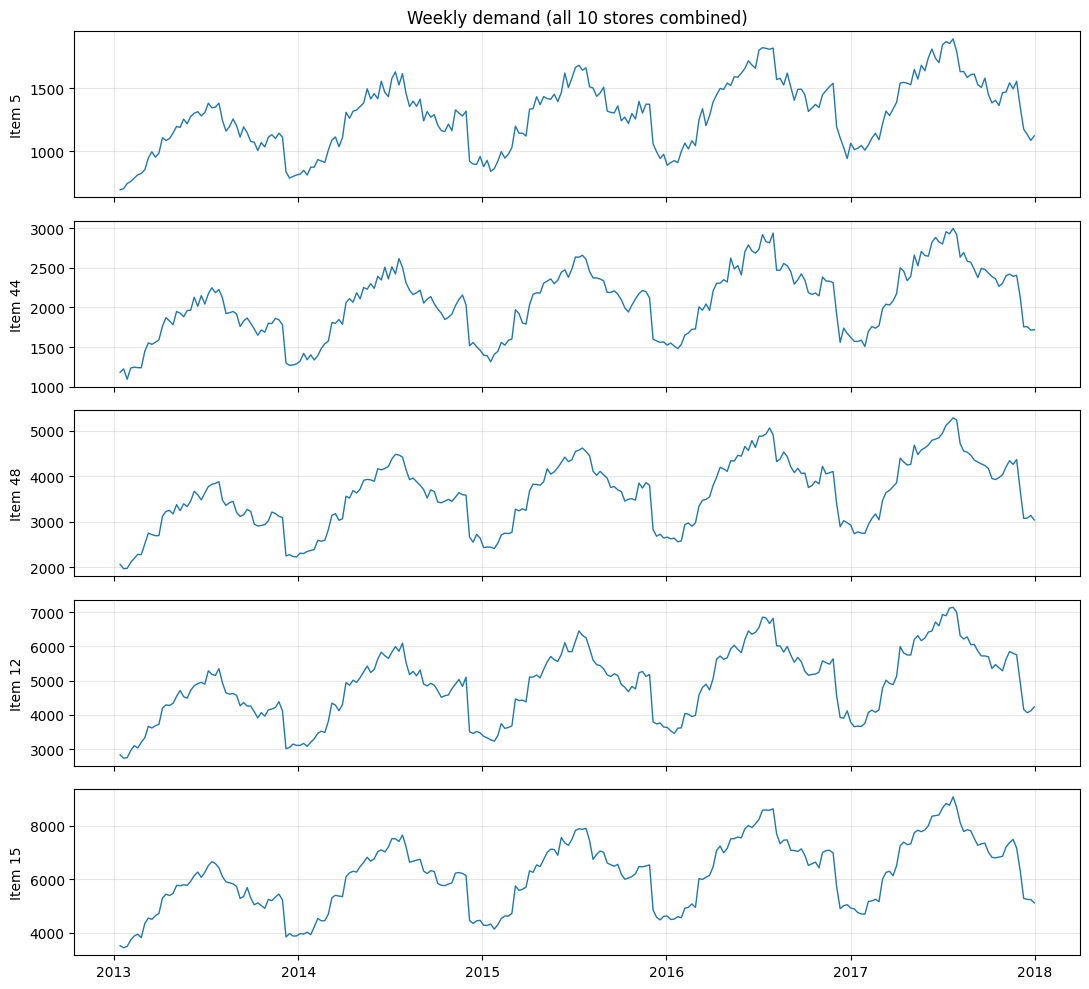

In [61]:
fig, axes = plt.subplots(len(items), 1, figsize=(11, 10), sharex=True)
for ax, item in zip(axes, items):
    ax.plot(wide.index, wide[item], linewidth=1)
    ax.set_ylabel(f"Item {item}")
    ax.grid(alpha=0.3)
axes[0].set_title("Weekly demand (all 10 stores combined)")
plt.tight_layout()
plt.show()

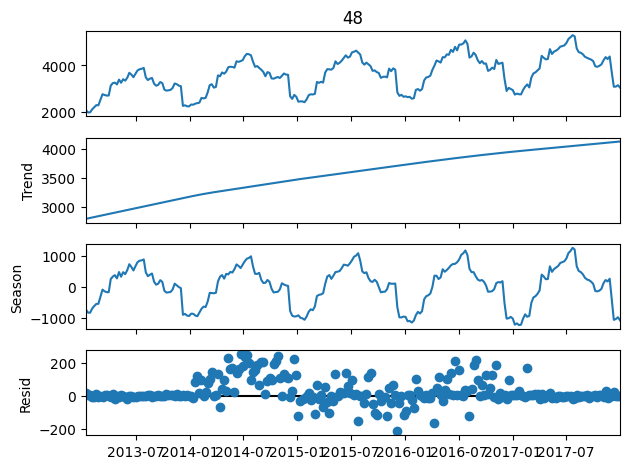

Std of trend:    382.9
Std of seasonal: 624.5
Std of residual: 75.2


In [62]:
from statsmodels.tsa.seasonal import STL

item = items[2]  # the median-volume item
# period=52: the seasonal pattern repeats every ~52 weeks
# robust=True: stops odd weeks from distorting the estimates
res = STL(wide[item], period=52, robust=True).fit()
res.plot()
plt.show()

# How big is each component relative to the whole series?
print("Std of trend:   ", res.trend.std().round(1))
print("Std of seasonal:", res.seasonal.std().round(1))
print("Std of residual:", res.resid.std().round(1))

### 1.4 Train/test split by date

In [63]:
TEST_WEEKS = 52

train = wide.iloc[:-TEST_WEEKS]   # everything except the last 52 weeks
test  = wide.iloc[-TEST_WEEKS:]   # the final 52 weeks: our "future"

print("Train:", train.index.min().date(), "->", train.index.max().date(), f"({len(train)} weeks)")
print("Test: ", test.index.min().date(),  "->", test.index.max().date(),  f"({len(test)} weeks)")

Train: 2013-01-13 -> 2017-01-01 (208 weeks)
Test:  2017-01-08 -> 2017-12-31 (52 weeks)


## 2. Baselines at a 52-week horizon

### 2.1 Error metrics: MAE, WAPE and MAPE

In [64]:
def mae(actual, fc):
    """Mean absolute error: average miss, in units."""
    return np.mean(np.abs(actual - fc))

def wape(actual, fc):
    """Weighted APE: total absolute miss as a share of total demand."""
    return np.sum(np.abs(actual - fc)) / np.sum(actual)

def mape(actual, fc):
    """Mean APE: average of each week's % miss."""
    return np.mean(np.abs(actual - fc) / actual)

### 2.2 Seasonal naive (same week last year)

In [65]:
m = 52
snaive = {}
for item in items:
    last_year = train[item].iloc[-m:].values              # the final 52 training weeks (2016)
    snaive[item] = pd.Series(last_year, index=test.index)  # label them with the test dates

rows = []
for item in items:
    a, f = test[item].values, snaive[item].values
    rows.append({"item": item, "MAE": mae(a, f), "WAPE": wape(a, f), "MAPE": mape(a, f)})
res_snaive = pd.DataFrame(rows).set_index("item")
res_snaive.round(3)

,MAE,WAPE,MAPE
item,,,
5,60.596,0.042,0.044
44,90.596,0.039,0.039
48,164.212,0.040,0.041
12,205.365,0.037,0.037
15,260.269,0.038,0.038


### 2.3 Holt-Winters on a single item

In [66]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

item = items[2]
y = train[item].asfreq("W-SUN")   # tells statsmodels the data is weekly (avoids a frequency warning)

model = ExponentialSmoothing(
    y,
    trend="add",                  # linear trend (b_t)
    seasonal="add",               # additive seasonal effect (s_t)
    seasonal_periods=52,          # m = 52 weeks
    initialization_method="heuristic",  # sensible starting values from the first 2 seasons;
)                                       # estimating 52 starting values from 208 points is fragile
fit = model.fit()

# The three smoothing parameters (alpha, beta, gamma) the optimiser chose
print({k: round(v, 4) for k, v in fit.params.items() if k.startswith("smoothing")})

fc = fit.forecast(52)
assert fc.index.equals(test.index), "forecast dates don't line up with the test dates"

{'smoothing_level': 0.3586, 'smoothing_trend': 0.0001, 'smoothing_seasonal': 0.0001}


### 2.4 Holt-Winters on all five items (additive vs multiplicative seasonality)

In [67]:
hw, chosen = {}, {}
for item in items:
    y = train[item].asfreq("W-SUN")
    fits = {}
    for seas in ["add", "mul"]:
        fits[seas] = ExponentialSmoothing(
            y, trend="add", seasonal=seas, seasonal_periods=52,
            initialization_method="heuristic",
        ).fit()
    # Both variants have the same number of parameters, so comparing their
    # training sum of squared one-step errors (.sse) is fair. We NEVER look at the test set to choose.
    best = min(fits, key=lambda s: fits[s].sse)
    chosen[item] = best
    fc = fits[best].forecast(52)
    assert fc.index.equals(test.index)
    hw[item] = fc

print(chosen)   # which seasonality type won for each item

{5: 'mul', 44: 'mul', 48: 'mul', 12: 'mul', 15: 'mul'}


### 2.5 Scoring the baselines and diagnosing bias

In [68]:
rows = []
for item in items:
    a = test[item].values
    for name, fcs in [("Seasonal naive", snaive), ("Holt-Winters", hw)]:
        f = fcs[item].values
        rows.append({"item": item, "model": name,
                     "MAE": mae(a, f), "WAPE": wape(a, f), "MAPE": mape(a, f)})
res = pd.DataFrame(rows)

# Per-item table, then the average across items
print(res.pivot(index="item", columns="model", values=["MAE", "WAPE", "MAPE"]).round(3))
print(res.groupby("model")[["MAE", "WAPE", "MAPE"]].mean().round(3))

               MAE                        WAPE                        MAPE  \
model Holt-Winters Seasonal naive Holt-Winters Seasonal naive Holt-Winters   
item                                                                         
5           85.590         60.596        0.059          0.042        0.059   
12         273.102        205.365        0.050          0.037        0.051   
15         374.616        260.269        0.054          0.038        0.055   
44         129.382         90.596        0.056          0.039        0.058   
48         262.545        164.212        0.065          0.040        0.065   

                      
model Seasonal naive  
item                  
5              0.044  
12             0.037  
15             0.038  
44             0.039  
48             0.041  
                    MAE   WAPE   MAPE
model                                
Holt-Winters    225.047  0.057  0.057
Seasonal naive  156.208  0.039  0.040


In [69]:
# 1) Bias: average (forecast - actual) as % of mean demand.
#    Positive = over-forecasting, negative = under-forecasting.
rows = []
for item in items:
    a = test[item].values
    rows.append({"item": item, "HW type": chosen[item],
                 "SN bias %": 100 * (snaive[item].values - a).mean() / a.mean(),
                 "HW bias %": 100 * (hw[item].values - a).mean() / a.mean()})
print(pd.DataFrame(rows).set_index("item").round(1))

# 2) Does the error grow with horizon? Compare first 13 vs last 13 test weeks.
for name, fcs in [("Seasonal naive", snaive), ("Holt-Winters", hw)]:
    first = np.mean([wape(test[i].values[:13],  fcs[i].values[:13])  for i in items])
    last  = np.mean([wape(test[i].values[-13:], fcs[i].values[-13:]) for i in items])
    print(f"{name:15s} WAPE weeks 1-13: {first:.3f}   weeks 40-52: {last:.3f}")

     HW type  SN bias %  HW bias %
item                              
5        mul       -3.7        5.2
44       mul       -3.6        5.0
48       mul       -4.0        6.0
12       mul       -3.7        4.5
15       mul       -3.7        5.0
Seasonal naive  WAPE weeks 1-13: 0.037   weeks 40-52: 0.047
Holt-Winters    WAPE weeks 1-13: 0.070   weeks 40-52: 0.056


## 3. Forecasting at a 2-week horizon

Every forecast for week *t* uses only data up to week *t* − 2, matching the 2-week supplier lead time.

### 3.1 Setup

In [70]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)   # noisy with 52 seasonal terms; harmless here

H = 2                                    # horizon = supplier lead time (weeks)
n_train, n_total = len(train), len(wide) # 208, 260
target_pos = range(n_train, n_total)     # row positions of the 52 test weeks

### 3.2 Seasonal naive, 2 weeks ahead

In [71]:
sn2 = {item: pd.Series([wide[item].iloc[p - 52] for p in target_pos], index=test.index)
       for item in items}
print(all(np.allclose(sn2[i], snaive[i]) for i in items))   # expect True

True


### 3.3 Holt-Winters, refitted every week

In [72]:
hw2 = {}
for item in items:
    preds = []
    for p in target_pos:
        hist = wide[item].iloc[:p - H + 1].asfreq("W-SUN")  # data through week p-2 only
        f = ExponentialSmoothing(hist, trend="add", seasonal=chosen[item],
                                 seasonal_periods=52,
                                 initialization_method="heuristic").fit()
        preds.append(f.forecast(H).iloc[-1])                # the 2nd step = week p
    hw2[item] = pd.Series(preds, index=test.index)
    print("done", item)

done 5
done 44
done 48
done 12
done 15


### 3.4 Scoring helper and first results

In [73]:
def score(name, fcs):
    rows = []
    for item in items:
        a, f = test[item].values, fcs[item].values
        rows.append({"model": name, "item": item,
                     "MAE": mae(a, f), "WAPE": wape(a, f), "MAPE": mape(a, f)})
    return pd.DataFrame(rows)

results = pd.concat([score("Seasonal naive", sn2), score("Holt-Winters", hw2)])
print(results.groupby("model")[["MAE", "WAPE", "MAPE"]].mean().round(3))

# bias again: did re-fitting remove the +5% overshoot?
for item in items:
    a = test[item].values
    print(item, round(100 * (hw2[item].values - a).mean() / a.mean(), 1))

                    MAE   WAPE  MAPE
model                               
Holt-Winters    106.895  0.029  0.03
Seasonal naive  156.208  0.039  0.04
5 0.1
44 0.2
48 0.1
12 0.1
15 0.1


### 3.5 WAPE by item: Holt-Winters vs seasonal naive

In [74]:
pi = results.pivot(index="item", columns="model", values="WAPE")
pi["HW wins?"] = pi["Holt-Winters"] < pi["Seasonal naive"]
print(pi.round(3))

model  Holt-Winters  Seasonal naive  HW wins?
item                                         
5             0.033           0.042      True
12            0.026           0.037      True
15            0.023           0.038      True
44            0.035           0.039      True
48            0.026           0.040      True


### 3.6 Poisson GLM

#### 3.6.1 Calendar features (trend and yearly Fourier terms)

In [75]:
import statsmodels.api as sm

def calendar_features(dates, t0, K=3):
    """Intercept, linear time trend, and K pairs of yearly Fourier terms."""
    t = np.asarray((dates - t0).days / 7, dtype=float)    # weeks since the first week
    d = np.asarray(dates.dayofyear) / 365.25              # position within the year, 0..1
    X = pd.DataFrame({"const": 1.0, "t": t}, index=dates)
    for k in range(1, K + 1):
        X[f"sin{k}"] = np.sin(2 * np.pi * k * d)
        X[f"cos{k}"] = np.cos(2 * np.pi * k * d)
    return X

X_all = calendar_features(wide.index, wide.index[0], K=3)
X_all.head(3)

,const,t,sin1,cos1,sin2,cos2,sin3,cos3
date,,,,,,,,
2013-01-13,1.0,0.0,0.221772,0.975099,0.432499,0.901634,0.621687,0.783266
2013-01-20,1.0,1.0,0.337301,0.941397,0.635068,0.772456,0.858402,0.512978
2013-01-27,1.0,2.0,0.447945,0.894061,0.800980,0.598691,0.984306,0.176471


#### 3.6.2 Fitting one item and reading the coefficients

In [76]:
item = items[2]
fit_glm = sm.GLM(wide[item].iloc[:n_train], X_all.iloc[:n_train],
                 family=sm.families.Poisson()).fit()      # Poisson family -> log link by default
print(fit_glm.params.round(4))

# Turn the trend coefficient into something a planner understands
b1 = fit_glm.params["t"]
print("Growth per year: ", round(100 * (np.exp(52 * b1) - 1), 1), "%")

const    7.9737
t        0.0016
sin1    -0.0453
cos1    -0.2390
sin2    -0.0570
cos2    -0.0268
sin3    -0.0468
cos3    -0.0361
dtype: float64
Growth per year:  8.4 %


#### 3.6.3 Rolling 2-week-ahead forecasts

In [77]:
glm2 = {}
for item in items:
    preds = []
    for p in target_pos:
        tr = slice(0, p - H + 1)           # positions 0..p-2: data through week p-2 only
        mdl = sm.GLM(wide[item].iloc[tr], X_all.iloc[tr],
                     family=sm.families.Poisson()).fit()
        preds.append(mdl.predict(X_all.iloc[[p]]).iloc[0])   # features for week p are known in advance
    glm2[item] = pd.Series(preds, index=test.index)

results = pd.concat([results, score("Poisson GLM", glm2)])
print(results.groupby("model")[["MAE", "WAPE", "MAPE"]].mean().round(3))
for item in items:
    a = test[item].values
    print(item, "GLM bias %:", round(100 * (glm2[item].values - a).mean() / a.mean(), 1))

                    MAE   WAPE   MAPE
model                                
Holt-Winters    106.895  0.029  0.030
Poisson GLM     174.828  0.043  0.045
Seasonal naive  156.208  0.039  0.040
5 GLM bias %: 3.3
44 GLM bias %: 3.2
48 GLM bias %: 3.2
12 GLM bias %: 3.2
15 GLM bias %: 3.3


#### 3.6.4 Did growth slow down?

In [78]:
yearly = wide.sum(axis=1).groupby(wide.index.year).sum()   # all 5 items combined, per calendar year
print(yearly)
print((yearly.pct_change() * 100).round(1))                # % growth vs previous year

date
2013     769210
2014     895800
2015     935594
2016    1011977
2017    1067103
dtype: int64
date
2013     NaN
2014    16.5
2015     4.4
2016     8.2
2017     5.4
dtype: float64


### 3.7 LightGBM

In [79]:
import lightgbm as lgb

#### 3.7.1 Lag, rolling-mean and calendar features

In [80]:
def build_features(s, H=2):
    """s: weekly demand for ONE item (a pd.Series with a date index).
    Every feature for row t uses data from week t-H or earlier."""
    L = s.shift(H).rolling(4).mean()        # shift FIRST, then roll: mean of y_{t-2..t-5}
    f = pd.DataFrame(index=s.index)
    f["y"], f["L"] = s, L
    f["target"] = s / L                     # what the model predicts (a ratio, close to 1)
    f["lag2"] = s.shift(2) / L
    f["lag3"] = s.shift(3) / L
    f["lag4"] = s.shift(4) / L
    f["lag52"] = s.shift(52) / L
    f["ly_ratio"] = f["target"].shift(52)   # last year's same-week ratio
    f["growth"] = L / L.shift(52)           # level now vs a year ago
    f["roll8"] = s.shift(2).rolling(8).mean() / L
    f["woy"] = s.index.isocalendar().week.astype(int).values
    d = s.index.dayofyear.values / 365.25
    f["sin1"], f["cos1"] = np.sin(2 * np.pi * d), np.cos(2 * np.pi * d)
    return f

feature_cols = ["lag2", "lag3", "lag4", "lag52", "ly_ratio", "growth", "roll8",
                "woy", "sin1", "cos1"]

frames = []
for item in items:
    f = build_features(wide[item])
    f["item"], f["pos"] = item, np.arange(len(f))   # pos = row position (week number)
    frames.append(f)
panel = pd.concat(frames).dropna(subset=feature_cols + ["target"])

print(panel.shape)                 # roughly 5 items x ~203 rows
panel[["pos"] + feature_cols].describe().loc[["min", "max"]].round(2)

(1015, 15)


,pos,lag2,lag3,lag4,lag52,ly_ratio,growth,roll8,woy,sin1,cos1
min,57.0,0.76,0.83,0.89,0.60,0.67,0.99,0.91,1.0,-1.0,-1.0
max,259.0,1.18,1.11,1.21,1.22,1.29,1.18,1.21,53.0,1.0,1.0


#### 3.7.2 Leakage test

In [81]:
s = wide[items[0]].copy()
q = 150                                           # an arbitrary week

base = build_features(s).iloc[q][feature_cols]

# Corrupt week q-1 and everything after. Features for week q must NOT change.
s_future = s.copy()
s_future.iloc[q - 1:] = 1e6
after = build_features(s_future).iloc[q][feature_cols]
print("Features unchanged by the future:", np.allclose(base, after, equal_nan=True))   # expect True

# Positive control: corrupting week q-2 (which IS allowed to matter) should change them
s_past = s.copy()
s_past.iloc[q - 2] = 1e6
print("Features react to allowed data:  ", not np.allclose(base, build_features(s_past).iloc[q][feature_cols]))  # expect True

Features unchanged by the future: True
Features react to allowed data:   True


#### 3.7.3 Rolling 2-week-ahead forecasts with weekly refits

In [82]:
def rolling_lgb(positions, params):
    out = {item: [] for item in items}
    for p in positions:
        tr = panel[panel["pos"] <= p - H]                   # target weeks known by the forecast date
        model = lgb.LGBMRegressor(**params).fit(tr[feature_cols], tr["target"])
        row = panel[panel["pos"] == p]                      # features for week p (built from <= p-2)
        ratio = model.predict(row[feature_cols])
        for item, r, L in zip(row["item"], ratio, row["L"]):
            out[item].append(r * L)                         # back to units: ratio x level
    idx = wide.index[list(positions)]
    return {item: pd.Series(v, index=idx) for item, v in out.items()}

def wape_of(fcs, positions):
    idx = wide.index[list(positions)]
    return np.mean([wape(wide[i].loc[idx].values, fcs[i].values) for i in items])

#### 3.7.4 Rolling-origin backtest on 2016 (hyperparameter choice)

In [83]:
val_pos = range(n_train - 52, n_train)           # weeks 156..207 (2016)

base_params = dict(random_state=0, verbose=-1, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8)
candidates = {
    "A: 4 leaves, 200 trees": dict(n_estimators=200, learning_rate=0.05, num_leaves=4,  min_child_samples=20),
    "B: 8 leaves, 200 trees": dict(n_estimators=200, learning_rate=0.05, num_leaves=8,  min_child_samples=20),
    "C: 4 leaves, 400 trees": dict(n_estimators=400, learning_rate=0.03, num_leaves=4,  min_child_samples=20),
}

val_scores = {}
for name, cp in candidates.items():
    fc = rolling_lgb(val_pos, {**base_params, **cp})
    val_scores[name] = wape_of(fc, val_pos)
    print(name, "-> validation WAPE", round(val_scores[name], 4))

best = min(val_scores, key=val_scores.get)
print("Chosen:", best)

A: 4 leaves, 200 trees -> validation WAPE 0.0282
B: 8 leaves, 200 trees -> validation WAPE 0.0264
C: 4 leaves, 400 trees -> validation WAPE 0.0278
Chosen: B: 8 leaves, 200 trees


#### 3.7.5 Scoring LightGBM on the 2017 test set

In [84]:
best_params = {**base_params, **candidates[best]}
lgb2 = rolling_lgb(target_pos, best_params)

results = pd.concat([results, score("LightGBM", lgb2)])
print(results.groupby("model")[["MAE", "WAPE", "MAPE"]].mean().round(3).sort_values("WAPE"))
for item in items:
    a = test[item].values
    print(item, "LGBM bias %:", round(100 * (lgb2[item].values - a).mean() / a.mean(), 1))

                    MAE   WAPE   MAPE
model                                
LightGBM         69.953  0.019  0.020
Holt-Winters    106.895  0.029  0.030
Seasonal naive  156.208  0.039  0.040
Poisson GLM     174.828  0.043  0.045
5 LGBM bias %: 0.4
44 LGBM bias %: 0.7
48 LGBM bias %: 0.7
12 LGBM bias %: 0.6
15 LGBM bias %: 0.7


### 3.8 Final model comparison

In [85]:
# One row per model: the average of each metric across the 5 items
summary = results.groupby("model")[["MAE", "WAPE", "MAPE"]].mean()

# Bias per model: average (forecast - actual) as a % of average demand
fc_sets = {"Seasonal naive": sn2, "Holt-Winters": hw2, "Poisson GLM": glm2, "LightGBM": lgb2}
summary["Bias %"] = pd.Series({
    name: np.mean([100 * (fcs[i].values - test[i].values).mean() / test[i].values.mean()
                   for i in items])
    for name, fcs in fc_sets.items()
})

summary = summary.sort_values("WAPE")
summary[["WAPE", "MAPE"]] *= 100                  # show as percentages
print(summary.round(2))

# Per-item WAPE, so we can see whether the winner is consistent
per_item = results.pivot(index="item", columns="model", values="WAPE").mul(100).round(2)
per_item["Best"] = per_item.idxmin(axis=1)
print(per_item)

summary.round(3).to_csv("results_table.csv")      # saved for the README later

                   MAE  WAPE  MAPE  Bias %
model                                     
LightGBM         69.95  1.95  1.98    0.61
Holt-Winters    106.89  2.86  3.01    0.09
Seasonal naive  156.21  3.93  3.98   -3.77
Poisson GLM     174.83  4.32  4.48    3.24
model  Holt-Winters  LightGBM  Poisson GLM  Seasonal naive      Best
item                                                                
5              3.33      2.54         4.42            4.17  LightGBM
12             2.59      1.63         4.33            3.74  LightGBM
15             2.26      1.38         4.27            3.75  LightGBM
44             3.48      2.41         4.15            3.92  LightGBM
48             2.64      1.76         4.45            4.05  LightGBM


## 4. Inventory planning

### 4.1 Saving forecasts (avoids re-running the refits after a kernel restart)

In [86]:
import pickle
with open("forecasts_2wk.pkl", "wb") as f:       # saved next to the notebook; keep it out of Git
    pickle.dump({"sn2": sn2, "hw2": hw2, "glm2": glm2, "lgb2": lgb2,
                 "results": results, "items": items, "best_params": best_params}, f)
print("saved")

saved


### 4.2 Forecast errors: standard deviation and independence check

In [87]:
from scipy.stats import norm
print("z for 95%:", round(norm.ppf(0.95), 3))      # should print 1.645

val_fc = rolling_lgb(val_pos, best_params)         # 2-week-ahead forecasts for 2016, trained on earlier weeks only
val_idx = wide.index[list(val_pos)]

sigma = {}
for item in items:
    e_val  = wide[item].loc[val_idx].values - val_fc[item].values   # actual - forecast (2016)
    e_test = test[item].values - lgb2[item].values                  # 2017, for comparison only
    sigma[item] = e_val.std(ddof=1)
    ac1 = np.corrcoef(e_val[:-1], e_val[1:])[0, 1]                  # do errors in consecutive weeks move together?
    print(f"item {item}: sigma 2016 = {sigma[item]:6.1f} | sigma 2017 = {e_test.std(ddof=1):6.1f} "
          f"| mean error 2016 = {e_val.mean():6.1f} | lag-1 autocorr = {ac1:5.2f}")

z for 95%: 1.645
item 5: sigma 2016 =   57.1 | sigma 2017 =   45.6 | mean error 2016 =    7.5 | lag-1 autocorr =  0.02
item 44: sigma 2016 =   95.7 | sigma 2017 =   65.3 | mean error 2016 =   14.4 | lag-1 autocorr =  0.02
item 48: sigma 2016 =  101.0 | sigma 2017 =   87.4 | mean error 2016 =   31.4 | lag-1 autocorr =  0.10
item 12: sigma 2016 =  153.6 | sigma 2017 =  105.8 | mean error 2016 =   42.9 | lag-1 autocorr =  0.13
item 15: sigma 2016 =  212.7 | sigma 2017 =  115.6 | mean error 2016 =   51.5 | lag-1 autocorr =  0.07


### 4.3 Safety stock and reorder point (formula)

In [88]:
z, L = 1.645, 2                                    # 95% service level; lead time in weeks
rows = []
for item in items:
    mean_fc = lgb2[item].mean()                    # average forecast weekly demand in 2017
    ss  = z * sigma[item] * np.sqrt(L)             # safety stock = z * sigma * sqrt(L)
    rop = L * mean_fc + ss                         # reorder point = lead-time demand + safety stock
    rows.append({"item": item, "mean weekly forecast": mean_fc, "sigma": sigma[item],
                 "safety stock": ss, "reorder point": rop,
                 "SS % of lead-time demand": 100 * ss / (L * mean_fc)})
ss_table = pd.DataFrame(rows).set_index("item")
print(ss_table.round(1))

      mean weekly forecast  sigma  safety stock  reorder point  \
item                                                             
5                   1460.0   57.1         132.7         3052.7   
44                  2330.0   95.7         222.7         4882.6   
48                  4083.3  101.0         234.9         8401.4   
12                  5515.6  153.6         357.2        11388.4   
15                  6983.8  212.7         494.9        14462.6   

      SS % of lead-time demand  
item                            
5                          4.5  
44                         4.8  
48                         2.9  
12                         3.2  
15                         3.5  


### 4.4 Monte Carlo safety stock vs the formula

In [89]:
# 2016 two-week-ahead errors (actual - forecast), one array per item: the error distribution
# a planner would have seen BEFORE 2017
err_pool = {i: wide[i].loc[val_idx].values - val_fc[i].values for i in items}

def lead_time_demand(mean_wk, pool, lead_probs, n=200_000, seed=1):
    """Simulate total demand over one supplier lead time, n times.
    lead_probs[k] = probability that the lead time is k+1 weeks."""
    rng = np.random.default_rng(seed)
    max_L = len(lead_probs)
    Ls = rng.choice(np.arange(1, max_L + 1), size=n, p=lead_probs)   # lead time of each trial
    e = rng.choice(pool, size=(n, max_L))                            # a random past error for each possible week
    in_window = np.arange(max_L)[None, :] < Ls[:, None]              # only weeks inside the lead time count
    return ((mean_wk + e) * in_window).sum(axis=1)

rows, ss_mc = [], {}
for item in items:
    m = lgb2[item].mean()                                            # average forecast weekly demand
    ltd = lead_time_demand(m, err_pool[item], [0, 1, 0])             # lead time fixed at 2 weeks
    ss_mc[item] = np.percentile(ltd, 95) - 2 * m                     # 95th percentile minus expected demand
    ltd_v = lead_time_demand(m, err_pool[item], [0.2, 0.6, 0.2])     # lead time 1, 2 or 3 weeks
    rows.append({"item": item, "SS formula": ss_table.loc[item, "safety stock"],
                 "SS Monte Carlo": ss_mc[item],
                 "SS MC, variable lead": np.percentile(ltd_v, 95) - 2 * m})
cmp = pd.DataFrame(rows).set_index("item")
cmp["MC vs formula %"] = 100 * (cmp["SS Monte Carlo"] / cmp["SS formula"] - 1)
print(cmp.round(1))

      SS formula  SS Monte Carlo  SS MC, variable lead  MC vs formula %
item                                                                   
5          132.7           155.3                1545.6             17.0
44         222.7           267.2                2475.5             20.0
48         234.9           310.0                4293.8             32.0
12         357.2           476.5                5808.9             33.4
15         494.9           615.3                7368.7             24.3


### 4.5 Inventory simulator

In [90]:
def simulate(f, pool, ss, L=2, lead_probs=None, n_runs=2000, warm=4, seed=0):
    """Simulate weekly inventory n_runs times over the forecast path f.
    Policy: each week, order up to (forecast demand over the next L weeks + ss)."""
    rng = np.random.default_rng(seed)
    f = np.asarray(f, dtype=float)
    T = len(f) + warm                                    # warm-up weeks so we start in steady state
    f_path = np.concatenate([np.full(warm, f[0]), f])
    f_pad = np.concatenate([f_path, np.full(L + 4, f_path[-1])])
    next_L = sum(f_pad[1 + k: 1 + k + T] for k in range(L))   # forecast demand over the next L weeks
    target = next_L + ss                                 # order-up-to level (= reorder level)

    demand = np.maximum(f_path + rng.choice(pool, size=(n_runs, T)), 0)   # forecast + a random past error
    if lead_probs is None:
        lead = np.full((n_runs, T), L)                   # fixed lead time
    else:
        lead = rng.choice(np.arange(1, len(lead_probs) + 1), size=(n_runs, T), p=lead_probs)

    arrivals = np.zeros((n_runs, T + 4))                 # arrivals[:, t] = units arriving at start of week t
    on_hand = np.full(n_runs, target[0])
    inv_start = np.zeros((n_runs, T)); inv_end = np.zeros((n_runs, T))
    sold = np.zeros((n_runs, T));      lost = np.zeros((n_runs, T))
    rows_ = np.arange(n_runs)
    for t in range(T):
        on_hand = on_hand + arrivals[:, t]               # receive deliveries
        inv_start[:, t] = on_hand
        sold[:, t] = np.minimum(on_hand, demand[:, t])   # sell what we have
        lost[:, t] = demand[:, t] - sold[:, t]           # the rest is a lost sale (stockout)
        on_hand = on_hand - sold[:, t]
        inv_end[:, t] = on_hand
        pipeline = arrivals[:, t + 1:].sum(axis=1)       # already on order
        order = np.maximum(target[t] - (on_hand + pipeline), 0)
        arrivals[rows_, t + lead[:, t]] += order         # arrives after the lead time
    k = slice(warm, T)                                   # report only the 52 real weeks
    return {"stockout": 100 * (lost[:, k] > 0).mean(),
            "fill": 100 * (sold[:, k].sum(axis=1) / demand[:, k].sum(axis=1)).mean(),
            "avg_inv": ((inv_start[:, k] + inv_end[:, k]) / 2).mean(),
            "inv_end": inv_end[:, k]}                    # kept for the inventory chart later

### 4.6 Simulator sanity tests

In [91]:
# Test 1: perfect forecasts and no safety stock -> should never stock out
r = simulate(np.full(52, 1000.0), np.zeros(10), ss=0, n_runs=50)
print("Perfect forecast -> stockout %, fill %:", r["stockout"], r["fill"])      # expect 0.0 and 100.0

# Test 2: more safety stock must never increase stockouts (same random draws each time)
so = [simulate(lgb2[5].values, err_pool[5], s)["stockout"] for s in (0, 100, 300, 1000)]
print("Stockout % as SS rises:", np.round(so, 1), "| decreasing:", all(a >= b for a, b in zip(so, so[1:])))

Perfect forecast -> stockout %, fill %: 0.0 100.0
Stockout % as SS rises: [44.3 11.9  0.1  0. ] | decreasing: True


### 4.7 Policy comparison: with vs without safety stock

In [92]:
A, B = "Fixed 2-wk lead time", "Variable lead time 1-3 wks"
scen = {A: None, B: [0.2, 0.6, 0.2]}      # B: 20% 1 week, 60% 2 weeks, 20% 3 weeks
out = []
for sname, probs in scen.items():
    for item in items:
        for pol, s_ in [("No safety stock", 0.0), ("With safety stock", ss_mc[item])]:
            r = simulate(lgb2[item].values, err_pool[item], s_, lead_probs=probs)
            out.append({"scenario": sname, "item": item, "policy": pol, "stockout %": r["stockout"],
                        "fill %": r["fill"], "avg inventory": r["avg_inv"]})
sim = pd.DataFrame(out)
sim.round(3).to_csv("simulation_results.csv", index=False)

for sname in scen:
    a = sim[sim.scenario == sname]
    no, ws = a[a.policy == "No safety stock"], a[a.policy == "With safety stock"]
    extra = 100 * (ws["avg inventory"].sum() / no["avg inventory"].sum() - 1)
    print(f"{sname}: stockout weeks {no['stockout %'].mean():.1f}% -> {ws['stockout %'].mean():.1f}% | "
          f"fill {no['fill %'].mean():.2f}% -> {ws['fill %'].mean():.2f}% | inventory +{extra:.1f}%")
sim[sim.scenario == A].round(2)

Fixed 2-wk lead time: stockout weeks 48.2% -> 4.3% | fill 98.55% -> 99.90% | inventory +13.7%
Variable lead time 1-3 wks: stockout weeks 43.6% -> 16.6% | fill 87.44% -> 89.21% | inventory +9.2%


,scenario,item,policy,stockout %,fill %,avg inventory
0,Fixed 2-wk lead time,5,No safety stock,44.29,98.41,753.88
1,Fixed 2-wk lead time,5,With safety stock,4.19,99.89,876.37
2,Fixed 2-wk lead time,44,No safety stock,45.84,98.36,1201.25
3,Fixed 2-wk lead time,44,With safety stock,4.19,99.87,1415.17
4,Fixed 2-wk lead time,48,No safety stock,51.86,98.72,2073.97
5,Fixed 2-wk lead time,48,With safety stock,4.36,99.94,2308.37
6,Fixed 2-wk lead time,12,No safety stock,49.17,98.67,2805.67
7,Fixed 2-wk lead time,12,With safety stock,4.32,99.91,3177.92
8,Fixed 2-wk lead time,15,No safety stock,49.74,98.61,3563.01
9,Fixed 2-wk lead time,15,With safety stock,4.33,99.90,4041.43


### 4.8 Service level vs inventory trade-off

In [93]:
rows = []
for sl in [0.50, 0.80, 0.90, 0.95, 0.99]:
    res = []
    for item in items:
        m = lgb2[item].mean()
        ltd = lead_time_demand(m, err_pool[item], [0, 1, 0])
        ss_sl = max(np.percentile(ltd, 100 * sl) - 2 * m, 0)       # SS for this service level
        r = simulate(lgb2[item].values, err_pool[item], ss_sl)
        res.append((r["stockout"], r["fill"], r["avg_inv"] / m))    # inventory in weeks of demand
    rows.append({"service level": f"{sl:.0%}",
                 **dict(zip(["stockout %", "fill %", "weeks of cover"], np.mean(res, axis=0)))})
tradeoff = pd.DataFrame(rows).set_index("service level")
tradeoff.round(2)

,stockout %,fill %,weeks of cover
service level,,,
50%,39.25,98.88,0.52
80%,16.15,99.59,0.55
90%,8.28,99.80,0.57
95%,4.28,99.90,0.59
99%,0.94,99.98,0.62


## 5. Result Charts

      avg weekly forecast  safety stock (formula)  safety stock (Monte Carlo)  \
item                                                                            
5                  1460.0                   133.0                       155.0   
44                 2330.0                   223.0                       267.0   
48                 4083.0                   235.0                       310.0   
12                 5516.0                   357.0                       476.0   
15                 6984.0                   495.0                       615.0   

      reorder point (formula)  reorder point (Monte Carlo)  
item                                                        
5                      3053.0                       3075.0  
44                     4883.0                       4927.0  
48                     8401.0                       8477.0  
12                    11388.0                      11508.0  
15                    14463.0                      14583.0  


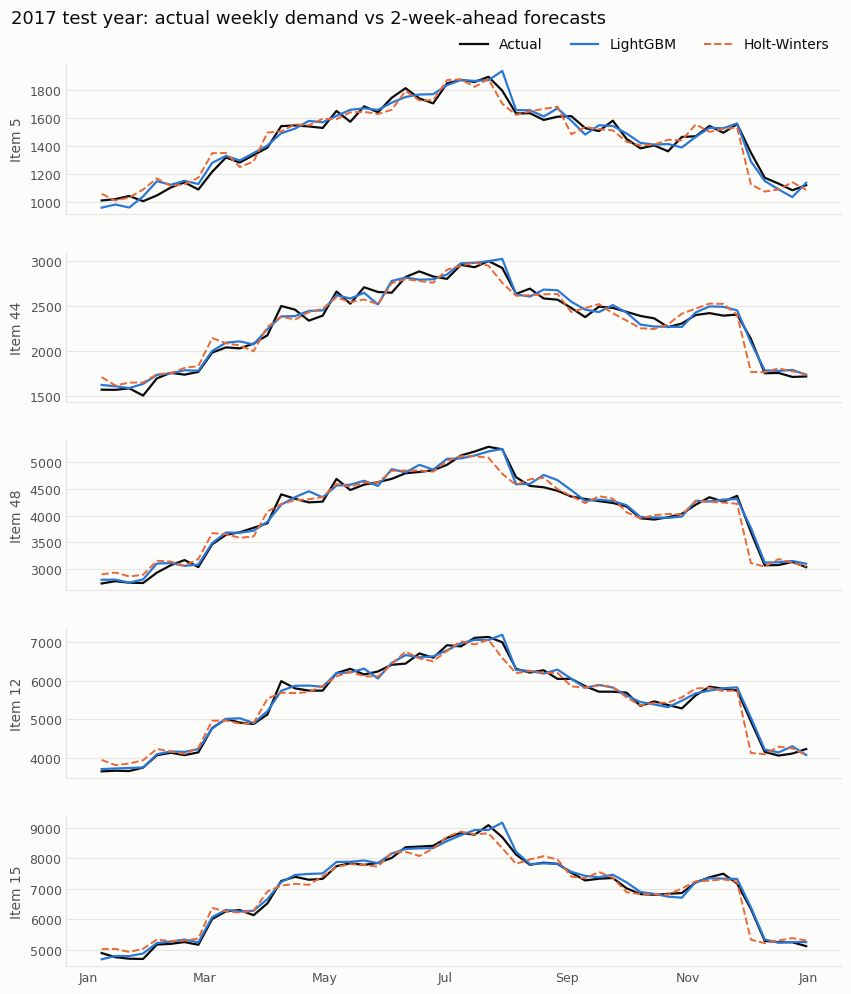

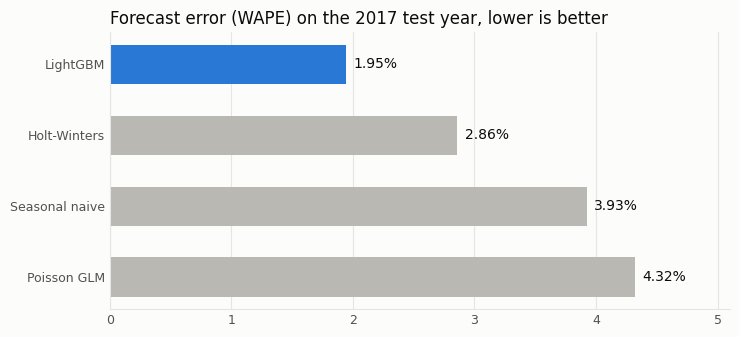

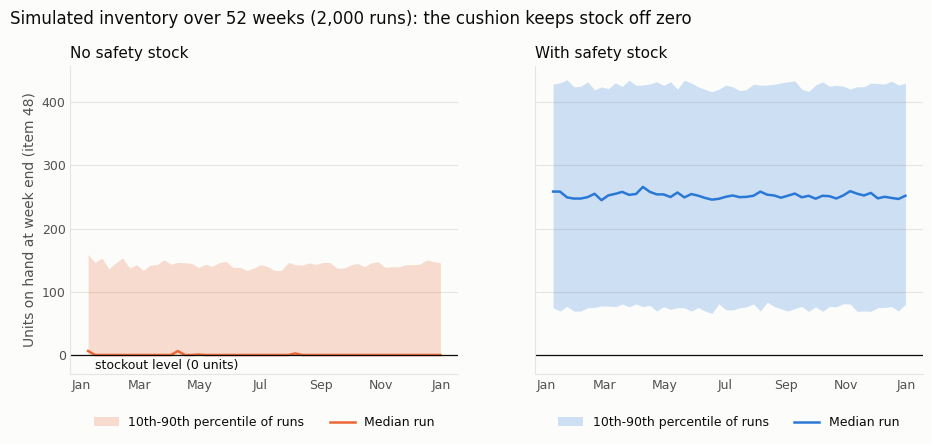

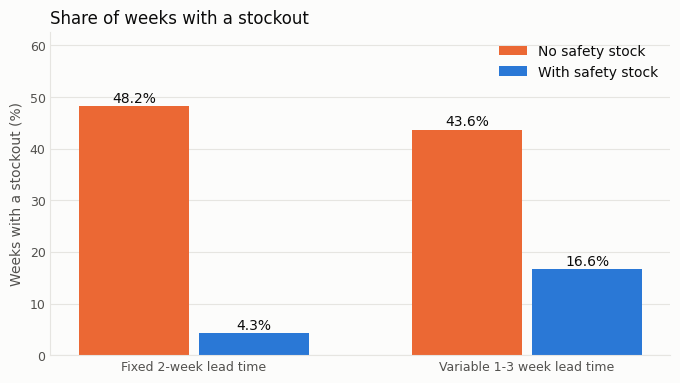

In [94]:
# ---------- Chunk 37: reorder-point table, saved results, and the four README charts ----------
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path("..") if Path("../data").exists() else Path(".")      # repo root, whether run from notebooks/ or the project folder
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

# Reorder points: lead-time demand at the 95th percentile (Monte Carlo) next to the formula version
rows = []
for item in items:
    m = lgb2[item].mean()
    ltd = lead_time_demand(m, err_pool[item], [0, 1, 0])
    rows.append({"item": item, "avg weekly forecast": m,
                 "safety stock (formula)": ss_table.loc[item, "safety stock"],
                 "safety stock (Monte Carlo)": ss_mc[item],
                 "reorder point (formula)": 2 * m + ss_table.loc[item, "safety stock"],
                 "reorder point (Monte Carlo)": np.percentile(ltd, 95)})
rop_table = pd.DataFrame(rows).set_index("item")
print(rop_table.round(0))

results.groupby("model")[["MAE", "WAPE", "MAPE"]].mean().round(4).to_csv(RES / "model_comparison.csv")
sim.round(3).to_csv(RES / "simulation_results.csv", index=False)
rop_table.round(1).to_csv(RES / "safety_stock_and_reorder_points.csv")
tradeoff.round(3).to_csv(RES / "service_level_tradeoff.csv")

# Chart style: two validated colours (blue, orange), neutral ink for text, recessive grid
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b2"
INK, MUTED, GRID, BG = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"

def style(ax, grid="y"):
    ax.set_facecolor(BG)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

# 1) Forecast vs actual, 2017 test year
fig, axes = plt.subplots(len(items), 1, figsize=(10, 11), sharex=True, facecolor=BG)
for ax, item in zip(axes, items):
    ax.plot(test.index, test[item], color=INK, lw=1.6, label="Actual")
    ax.plot(test.index, lgb2[item], color=BLUE, lw=1.6, label="LightGBM")
    ax.plot(test.index, hw2[item], color=ORANGE, lw=1.4, ls="--", label="Holt-Winters")
    ax.set_ylabel(f"Item {item}", color=MUTED); style(ax)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3, frameon=False, fontsize=10, labelcolor=INK)
fig.suptitle("2017 test year: actual weekly demand vs 2-week-ahead forecasts", x=0.07, ha="left", color=INK, fontsize=13)
fig.subplots_adjust(top=0.93, hspace=0.25)
fig.savefig(FIG / "1_forecast_vs_actual.png", dpi=150, bbox_inches="tight", facecolor=BG); plt.show()

# 2) Model comparison (WAPE, average of the 5 items; lower is better)
w = results.groupby("model")["WAPE"].mean().mul(100).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=BG)
bars = ax.barh(w.index, w.values, color=[BLUE if n == "LightGBM" else GREY for n in w.index], height=0.55)
ax.invert_yaxis(); style(ax, grid="x")
for b, v in zip(bars, w.values):
    ax.text(v + 0.06, b.get_y() + b.get_height() / 2, f"{v:.2f}%", va="center", color=INK, fontsize=10)
ax.set_xlim(0, w.max() * 1.18)
ax.set_title("Forecast error (WAPE) on the 2017 test year, lower is better", loc="left", color=INK, fontsize=12)
fig.savefig(FIG / "2_model_comparison.png", dpi=150, bbox_inches="tight", facecolor=BG); plt.show()

# 3) Simulated inventory over a year (median item by volume): 10th-90th percentile range and median of 2,000 runs
show = items[2]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, facecolor=BG)
for ax, (label, s_, col) in zip(axes, [("No safety stock", 0.0, ORANGE), ("With safety stock", ss_mc[show], BLUE)]):
    inv = simulate(lgb2[show].values, err_pool[show], s_)["inv_end"]          # end-of-week stock, shape (runs, 52)
    lo, med, hi = np.percentile(inv, [10, 50, 90], axis=0)
    ax.fill_between(test.index, lo, hi, color=col, alpha=0.22, lw=0, label="10th-90th percentile of runs")
    ax.plot(test.index, med, color=col, lw=1.8, label="Median run")
    ax.axhline(0, color=INK, lw=0.9)
    ax.set_title(label, loc="left", color=INK, fontsize=11); style(ax)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, fontsize=9, labelcolor=INK)
axes[0].set_ylim(bottom=-30)
axes[0].set_ylabel(f"Units on hand at week end (item {show})", color=MUTED)
axes[0].text(test.index[1], -6, "stockout level (0 units)", va="top", color=INK, fontsize=9)
fig.suptitle("Simulated inventory over 52 weeks (2,000 runs): the cushion keeps stock off zero", x=0.07, ha="left", color=INK, fontsize=12, y=1.02)
fig.savefig(FIG / "3_simulated_inventory.png", dpi=150, bbox_inches="tight", facecolor=BG); plt.show()

# 4) Stockout comparison (average of the 5 items)
agg = sim.groupby(["scenario", "policy"])["stockout %"].mean().unstack().loc[[A, B]]
x, bw = np.arange(2), 0.36
fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=BG)
for off, pol, col in [(-bw / 2, "No safety stock", ORANGE), (bw / 2, "With safety stock", BLUE)]:
    bars = ax.bar(x + off, agg[pol], bw * 0.92, color=col, label=pol)
    for b, v in zip(bars, agg[pol]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f}%", ha="center", color=INK, fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(["Fixed 2-week lead time", "Variable 1-3 week lead time"], color=INK)
ax.set_ylabel("Weeks with a stockout (%)", color=MUTED); style(ax)
ax.set_ylim(0, agg.values.max() * 1.3)
ax.legend(frameon=False, labelcolor=INK, loc="upper right")
ax.set_title("Share of weeks with a stockout", loc="left", color=INK, fontsize=12)
fig.savefig(FIG / "4_stockout_comparison.png", dpi=150, bbox_inches="tight", facecolor=BG); plt.show()